([(3, 2), (3, 3)], [[(3, 3), (3, 2)], [(3, 2)]])                                                                                    
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 4 (Circle)
Info    : [ 20%] Meshing curve 5 (Line)
Info    : [ 40%] Meshing curve 6 (Circle)
Info    : [ 60%] Meshing curve 7 (Circle)
Info    : [ 70%] Meshing curve 8 (Line)
Info    : [ 90%] Meshing curve 9 (Circle)
Info    : Done meshing 1D (Wall 0.000368916s, CPU 0.000389s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 4 (Cylinder, Frontal-Delaunay)
Info    : [ 20%] Meshing surface 5 (Plane, Frontal-Delaunay)
Info    : [ 40%] Meshing surface 6 (Plane, Frontal-Delaunay)
Info    : [ 60%] Meshing surface 7 (Cylinder, Frontal-Delaunay)
Info    : [ 70%] Meshing surface 8 (Plane, Frontal-Delaunay)
Info    : [ 90%] Meshing surface 9 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.5183s, CPU 0.515654s)
Info    : Meshing 3D...
Info    : 3D Meshing 2 volumes with 1 connected component


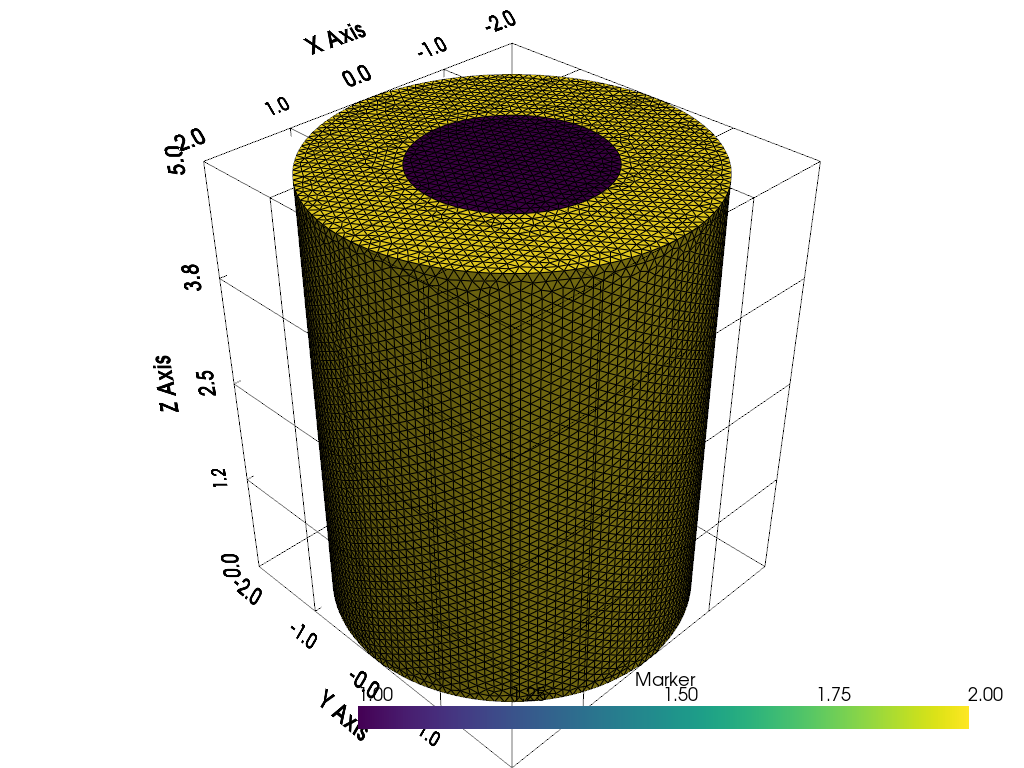

In [1]:
import gmsh
from mpi4py import MPI
from dolfinx.io import gmshio
import dolfinx 
import vtk
import pyvista
mesh_comm = MPI.COMM_WORLD
from petsc4py.PETSc import ScalarType

Lx = 5.
R_e = 2.0
R_i = 1.0
mesh_size = R_i/10
# Initialize the gmsh API
gmsh.initialize()
gdim = 3 
# Create a new model
model = gmsh.model()
model.add("Cylinder")
cell_names = {"inner": 1, "exterior": 2}

# Define parameters for the cylinder

cylinder_height = Lx

# Create a cylinder (Gmsh automatically adds a point at the center of the bottom circle)
outer_cylinder = model.occ.addCylinder(0.0, 0.0, 0.0, 0, 0, cylinder_height,  R_e)
inner_cylinder = model.occ.addCylinder(0.0, 0.0, 0.0, 0, 0, cylinder_height,  R_i)
whole_domain = gmsh.model.occ.fragment(
            [(gdim, outer_cylinder)], [(gdim, inner_cylinder)]
        )
# take the union of the two cylinders
model.occ.synchronize()
print(whole_domain)
inner_domain = whole_domain[0][0]
outer_domain = whole_domain[0][1]
model.addPhysicalGroup(gdim, [inner_domain[1]], tag=cell_names["inner"])
model.setPhysicalName(gdim, inner_domain[1], "inner")
model.addPhysicalGroup(gdim, [outer_domain[1]], tag=cell_names["exterior"])
model.setPhysicalName(gdim, outer_domain[1], "exterior")
#volumes = gmsh.model.getEntities(dim=3)
#marker_1 = 1 
#gmsh.model.addPhysicalGroup(volumes[0][0], [volumes[0][1]], 10)

gmsh.model.mesh.setOrder(1)
# Synchronize the CAD representation with the Gmsh model
model.occ.synchronize()
model.mesh.set_size(gmsh.model.getEntities(0), mesh_size)
model.mesh.generate(3)

# Write the model to a file (e.g., .msh or .geo)
gmsh.write("cylinder.msh")

# Finalize the Gmsh API
# gmsh.finalize()
model_rank = 0 
domain, cell_tags, facet_tags = gmshio.model_to_mesh(model, mesh_comm, model_rank, gdim=gdim)
domain.name = "composite"
cell_tags.name = f"{domain.name}_cells"
facet_tags.name = f"{domain.name}_facets"
gmsh.finalize()
topology, cells, geometry = dolfinx.plot.vtk_mesh(domain)
function_grid = pyvista.UnstructuredGrid(topology, cells, geometry)
function_grid["Marker"] = cell_tags.values
plotter = pyvista.Plotter()
plotter.add_mesh(function_grid, show_edges=True)
plotter.show_bounds(grid='front', location='outer', all_edges=True)
plotter.view_isometric()
plotter.show()


## Define the linear problem and solve
Let us generate a simple mesh. More complex and realistic meshes can be generated with [gmsh](http://gmsh.info/.)


In [2]:
import ufl 
import dolfinx.fem.petsc
import numpy as np

lmbda_1 = 2.
lmbda_2 = 1.
mu_1 = 20.
mu_2 = 1.

theta = 1.0

domain_dimension = domain.topology.dim
facet_dimension = domain.topology.dim - 1
print(f"We have a {domain_dimension}-d mesh with {facet_dimension}-d boundary")


ds = ufl.Measure("ds", domain=domain)
dx = ufl.Measure("dx", domain=domain, subdomain_data=cell_tags)

V = dolfinx.fem.functionspace(domain, ("Lagrange", 1, (domain_dimension, )))


uD = dolfinx.fem.Function(V)
uD.interpolate(lambda x: theta * np.array([-x[1], x[0], np.zeros_like(x[0])]))

def right(x):
    return np.isclose(x[2], Lx)

def left(x):
    return np.isclose(x[2], 0.0)

left_facets = dolfinx.mesh.locate_entities_boundary(domain, facet_dimension, left)
left_dofs = dolfinx.fem.locate_dofs_topological(V, facet_dimension, left_facets)
bc_value_left = np.array([0.0, 0.0, 0.0], dtype=ScalarType)
bc_left = dolfinx.fem.dirichletbc(bc_value_left, left_dofs, V)

right_facets = dolfinx.mesh.locate_entities_boundary(domain, facet_dimension, right)
right_dofs = dolfinx.fem.locate_dofs_topological(V, facet_dimension, right_facets)
bc_right = dolfinx.fem.dirichletbc(uD, right_dofs)

bcs = [bc_left,bc_right]


u = ufl.TrialFunction(V)
v = ufl.TestFunction(V)

x = ufl.SpatialCoordinate(domain)

def eps(u):
    return ufl.sym(ufl.grad(u))
    
def sigma(eps):
    x = ufl.SpatialCoordinate(domain)
    lambda_ = ufl.conditional(ufl.inner(x, x) < R_i**2, lmbda_1, lmbda_2)
    mu = ufl.conditional(ufl.inner(x, x) < R_i**2, mu_1, mu_2)
    return lambda_ * ufl.tr(eps) * ufl.Identity(domain_dimension) + 2 * mu * eps

def a(u,v):
    """The bilinear form of the weak formulation"""
    return ufl.inner(sigma(eps(u)), eps(v)) * dx

def L(v): 
    """The linear form of the weak formulation"""
    # Volume force
    b = ufl.as_vector([0, 0, 0])

    # Surface force on the top
    f = ufl.as_vector([0, 0, 0])
    #return ufl.dot(b, v) * dx + ufl.dot(f, v) * ds(1)    
    return dolfinx.fem.Constant(domain,0.0) * v[1] * dx(1) #+ ufl.dot(f, v) * ds

problem = dolfinx.fem.petsc.LinearProblem(a(u,v), L(v), bcs=bcs,) 
#                                    petsc_options={"ksp_type": "gmres", "pc_type": "gamg"})
uh = problem.solve()
uh.name = "displacement"

stress = sigma(eps(uh))
V_stress = dolfinx.fem.functionspace(domain, ("CG", 1, (3,3)))

stress_expr = dolfinx.fem.Expression(stress, V_stress.element.interpolation_points())
stress_function = dolfinx.fem.Function(V_stress,name="sigma")
stress_function.interpolate(stress_expr)



strain_expr = dolfinx.fem.Expression(eps(uh), V_stress.element.interpolation_points())
strain_function = dolfinx.fem.Function(V_stress,name="eps")
strain_function.interpolate(strain_expr)

with dolfinx.io.XDMFFile(MPI.COMM_WORLD, "output/elasticity-demo.xdmf", "w") as file:
    file.write_mesh(uh.function_space.mesh)
    file.write_function(uh)    
    file.write_function(strain_function)    
    file.write_function(stress_function)

We have a 3-d mesh with 2-d boundary


ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored


## Postprocessing

We can easily calculate the potential energy

In [3]:

elastic_energy = dolfinx.fem.assemble_scalar(dolfinx.fem.form(0.5 * a(uh, uh)))
print(f"The elastic energy energy is {elastic_energy:2.3f}")

external_work = dolfinx.fem.assemble_scalar(dolfinx.fem.form(L(uh)))
print(f"The external work is {external_work:2.3f}")

ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored


The elastic energy energy is 2.597


ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored


The external work is 0.000


Let us plot the solution using `pyvista`, see
- https://jorgensd.github.io/dolfinx-tutorial/chapter3/component_bc.html
- https://docs.fenicsproject.org/dolfinx/v0.5.0/python/demos/demo_pyvista.html

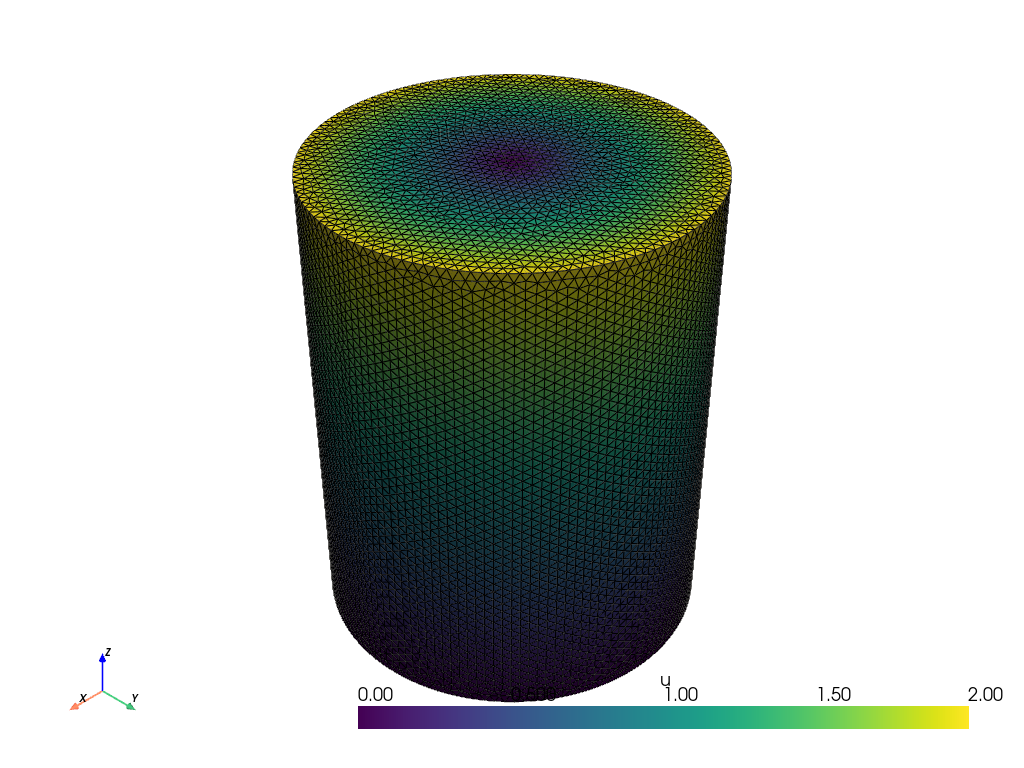

In [4]:
import vtk 
import pyvista
pyvista.xvfb.start_xvfb()
pyvista.set_jupyter_backend("static") #

# Create plotter and pyvista grid
p = pyvista.Plotter()
topology, cell_types, geometry = dolfinx.plot.vtk_mesh(V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)
actor_0 = p.add_mesh(grid, style="wireframe", color="gray",opacity=0.2,)
# Attach vector values to grid and warp grid by vector
values = np.zeros((geometry.shape[0], 3))
values[:, :len(uh)] = uh.x.array.reshape(geometry.shape[0], len(uh))
grid["u"] = values
#actor_0 = p.add_mesh(grid, style="surface", color="gray",opacity=0.9)
warped = grid.warp_by_vector("u", factor=0.02)
actor_1 = p.add_mesh(warped, show_edges=True,show_scalar_bar=True)
p.show_axes()
p.view_isometric()
p.show()

## Stress computation

We calculate here the Von Mises stress by interpolating the corresponding ufl expression, see https://jorgensd.github.io/dolfinx-tutorial/chapter2/linearelasticity_code.html#stress-computation

In [ ]:
stress = sigma(eps(uh))
V_stress_scalar = dolfinx.fem.functionspace(domain, ("DG", 0))

stress_xx_expr = dolfinx.fem.Expression(ufl.inner(stress , stress) ** 0.5, V_stress_scalar.element.interpolation_points())
stress_xx_function = dolfinx.fem.Function(V_stress_scalar,name="sigmaxx")
stress_xx_function.interpolate(stress_xx_expr)
p = pyvista.Plotter()
actor_0 = p.add_mesh(grid, style="surface", color="gray",opacity=0.15,)

field_label = r"$\sigma_{xx}$"
warped.cell_data[field_label] = stress_xx_function.vector.array
warped.set_active_scalars(field_label)
p.add_mesh(warped, show_scalar_bar=False,show_edges=True,edge_opacity=.2,
           scalar_bar_args={'title': field_label, 'vertical': False, #'height': 0.5, 'width': 0.05, 
                            #'position_x': .9, 'position_y': 0.25
                            }
           )
p.show_axes()
p.view_isometric()
p.show()

ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored
ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-mmc/lib' ignored


AttributeError: 'Function' object has no attribute 'vector'

: 

Let us now wrap up the finite element solver in a function and plot the estimate as a function of the aspect ratio of the joint and compare with the analytical estimates.

In [ ]:
def k_equivalent_fem(Lx=0.1,nu=1./3.,mesh_size=0.05):
    """Compute the equivalent stiffness matrix from the displacement uh"""
    Ly = 1.
    E = 1.
    lambda_ = nu * E / ((1-2*nu) * (1+nu))
    mu = E/(2*(1+nu))
    u_d = -1.
    
    gmsh.initialize()
    gdim = 2
    gmsh.option.setNumber("Mesh.CharacteristicLengthMin",mesh_size)
    gmsh.option.setNumber("Mesh.CharacteristicLengthMax",mesh_size)
    rect = gmsh.model.occ.addRectangle(0, 0, 0, Lx, Ly)
    gmsh.model.occ.synchronize()
    gmsh.option.setNumber("Mesh.Algorithm", 5)
    gmsh.model.addPhysicalGroup(gdim, [rect], 1)
    gmsh.option.setNumber("General.Verbosity", 1)

    gmsh.model.mesh.generate(gdim)
    
    # set gmsh verbosity level
    gmsh.option.setNumber("General.Verbosity", 0)
    gmsh.option.setNumber("General.Terminal", 0)
    domain, cell_markers, facet_markers = gmshio.model_to_mesh(gmsh.model, MPI.COMM_WORLD, 0, gdim=gdim)
    #domain = dolfinx.mesh.create_rectangle(MPI.COMM_WORLD, [np.array([0,0]), np.array([L, W])],
    #                  [int(L/W)*ndiv,ndiv], cell_type=dolfinx.mesh.CellType.triangle)
    gmsh.finalize()
    domain_dimension = domain.topology.dim
    facet_dimension = domain.topology.dim - 1

    V = dolfinx.fem.functionspace(domain, ("Lagrange", 1, (domain.geometry.dim, )))
    
    def left(x):
        return np.isclose(x[0], 0.0)

    left_facets = dolfinx.mesh.locate_entities_boundary(domain, facet_dimension, left)
    left_dofs = dolfinx.fem.locate_dofs_topological(V, facet_dimension, left_facets)
    bc_value_left = np.array([0,0],dtype=ScalarType)
    bc_left = dolfinx.fem.dirichletbc(bc_value_left, left_dofs, V)

    def right(x):
        return np.isclose(x[0], Lx)
    
    right_facets = dolfinx.mesh.locate_entities_boundary(domain, facet_dimension, right)
    right_dofs = dolfinx.fem.locate_dofs_topological(V, facet_dimension, right_facets)
    bc_value_right = np.array([u_d,0],dtype=ScalarType)
    bc_right = dolfinx.fem.dirichletbc(bc_value_right, right_dofs, V)
    bcs = [bc_left, bc_right]

    mt = dolfinx.mesh.meshtags(domain, facet_dimension, right_facets, 1)
    ds = ufl.Measure("ds", subdomain_data=mt, domain=domain)
    dx = ufl.Measure("dx", domain=domain)

    u = ufl.TrialFunction(V)
    v = ufl.TestFunction(V)

    def eps(u):
        return ufl.sym(ufl.grad(u))

    def sigma(eps):
        return lambda_ * ufl.tr(eps) * ufl.Identity(2) + 2 * mu * eps

    def a(u,v):
        """The bilinear form of the weak formulation"""
        return ufl.inner(sigma(eps(u)), eps(v)) * dx

    def L(v): 
        """The linear form of the weak formulation"""
        # Volume force
        b = dolfinx.fem.Constant(domain,ScalarType((0, 0)))

        # Surface force on the top
        f = ufl.as_vector([0, 0])
        #return ufl.dot(b, v) * dx + ufl.dot(f, v) * ds(1)    
        return ufl.inner(b, v) * dx + ufl.dot(f, v) * ds

    problem = dolfinx.fem.petsc.LinearProblem(a(u,v), L(v), bcs=bcs, 
                                        petsc_options={"ksp_type": "gmres", "pc_type": "gamg"})
    uh = problem.solve()
    uh.name = "displacement"
    elastic_energy = dolfinx.fem.assemble_scalar(dolfinx.fem.form(0.5 * a(uh, uh)))
    print(f"Lx: {Lx:2.3f}, The elastic energy energy is {elastic_energy:2.3f}")

    return  elastic_energy * 2 / u_d **2 

k_equivalent_fem(Lx=1.0,nu=1./3.,mesh_size=0.05)

Ls = np.linspace(.1,3,20)
ks = [k_equivalent_fem(Lx,nu=1./3.,mesh_size=min([0.1,Lx/10])) for Lx in Ls]

# plot the results


Lx: 1.000, The elastic energy energy is 0.604
Lx: 0.100, The elastic energy energy is 7.285
Lx: 0.253, The elastic energy energy is 2.754
Lx: 0.405, The elastic energy energy is 1.643
Lx: 0.558, The elastic energy energy is 1.151
Lx: 0.711, The elastic energy energy is 0.881
Lx: 0.863, The elastic energy energy is 0.712
Lx: 1.016, The elastic energy energy is 0.597
Lx: 1.168, The elastic energy energy is 0.514
Lx: 1.321, The elastic energy energy is 0.450
Lx: 1.474, The elastic energy energy is 0.401
Lx: 1.626, The elastic energy energy is 0.362
Lx: 1.779, The elastic energy energy is 0.329
Lx: 1.932, The elastic energy energy is 0.302
Lx: 2.084, The elastic energy energy is 0.280
Lx: 2.237, The elastic energy energy is 0.260
Lx: 2.389, The elastic energy energy is 0.243
Lx: 2.542, The elastic energy energy is 0.228
Lx: 2.695, The elastic energy energy is 0.214
Lx: 2.847, The elastic energy energy is 0.203
Lx: 3.000, The elastic energy energy is 0.192
